# GoEmotions — kết quả tại checkpoint tốt nhất
Notebook tái hiện đánh giá từ điểm dự đoán đã lưu. Không huấn luyện lại và không tìm ngưỡng trên test. Checkpoint và ngưỡng đã được khóa bằng validation.

Bản đồng bộ báo cáo Final v6. Bảng chính dùng cấu hình chung, không chọn cấu hình tốt nhất riêng từng mô hình. Lịch tám epoch được quyết định sau khi test cũ đã được xem; xem `report_context.json` và `protocol_history/`.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "main_results").exists() and (ROOT.parent / "main_results").exists():
    ROOT = ROOT.parent
if not (ROOT / "main_results").exists() and (ROOT / "experiments/best_epochs_20261103/main_results").exists():
    ROOT = ROOT / "experiments/best_epochs_20261103"
MAIN = ROOT / "main_results"
read = lambda path: json.loads(path.read_text(encoding="utf-8"))
sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
lock = read(MAIN / "LOCK_BEFORE_TEST.json")
selection = read(MAIN / "selection.json")
assert sha(MAIN / "selection.json") == lock["selection_sha256"]
display(pd.DataFrame(selection["architecture_summaries_validation"]))
print("Mô hình demo:", selection["architecture"], "seed", selection["seed"])

,architecture,validation_macro_f1_mean,validation_macro_f1_std,parameter_count
0,roberta,0.480139,0.012193,124667164
1,distilbert,0.470032,0.003411,66975004
2,bert,0.460801,0.004375,108331804


Mô hình demo: roberta seed 2026


## 1. Tính lại chỉ số test từ đủ chín bộ điểm
Giữ đủ 28 nhãn, dùng `score ≥ threshold`; Macro-F1 gồm cả nhãn có F1 bằng 0. Hai chế độ ngưỡng được áp trên cùng một bộ điểm của từng checkpoint.

In [2]:
frame = pd.read_parquet(MAIN / "data/raw/test-00000-of-00001.parquet")
records = []
for run in lock["runs"]:
    protocol_path = MAIN / Path(run["protocol"].replace("\\", "/"))
    assert sha(protocol_path) == run["protocol_sha256"]
    protocol = read(protocol_path)
    folder = protocol_path.parent
    receipt = read(folder / "test_results.json")
    assert receipt["scores_sha256"] == sha(folder / "test_scores.npz")
    with np.load(folder / "test_scores.npz", allow_pickle=False) as saved:
        ids, points = saved["ids"].astype(str), saved["scores"]
        labels = saved["label_names"].astype(str).tolist()
    assert labels == protocol["label_names"] and len(labels) == 28
    by_id = dict(zip(frame.id.astype(str), frame.labels))
    truth = np.zeros_like(points, dtype=np.uint8)
    for i, ident in enumerate(ids): truth[i, by_id[ident]] = 1
    assert points.shape == truth.shape == (5427, 28)
    for config in protocol["configurations"]:
        if config["threshold_mode"] not in ("fixed", "tuned"): continue
        prediction = points >= np.asarray(config["thresholds"])
        row = dict(model=run["architecture"], seed=run["seed"], epoch=run["selected_epoch"], mode=config["threshold_mode"])
        for average in ("macro", "micro"):
            row[average+"_f1"] = f1_score(truth, prediction, average=average, zero_division=0)
            row[average+"_precision"] = precision_score(truth, prediction, average=average, zero_division=0)
            row[average+"_recall"] = recall_score(truth, prediction, average=average, zero_division=0)
        row["hamming_loss"] = hamming_loss(truth, prediction)
        records.append(row)
actual = pd.DataFrame(records)
csv = pd.read_csv(MAIN / "report_data/all_runs.csv")
for row in records:
    expected = csv[(csv.system == "C_"+row["model"]) & (csv.seed == row["seed"]) & (csv.split == "test") & (csv.threshold_mode == row["mode"])].iloc[0]
    for metric in ("macro_f1", "micro_f1", "macro_precision", "macro_recall", "micro_precision", "micro_recall", "hamming_loss"):
        assert abs(row[metric]-expected[metric]) < 1e-12
print("Đã đối chiếu 18 hàng test × 7 chỉ số từ điểm dự đoán thật.")
display(actual[["model", "seed", "epoch", "mode", "macro_f1", "micro_f1", "hamming_loss"]].round(4))

Đã đối chiếu 18 hàng test × 7 chỉ số từ điểm dự đoán thật.


,model,seed,epoch,mode,macro_f1,micro_f1,hamming_loss
0,bert,42,7,fixed,0.4745,0.5738,0.0333
1,bert,42,7,tuned,0.5022,0.5681,0.0410
2,bert,123,6,fixed,0.4707,0.5680,0.0331
3,bert,123,6,tuned,0.4911,0.5776,0.0387
4,bert,2026,7,fixed,0.4637,0.5701,0.0336
5,bert,2026,7,tuned,0.4881,0.5695,0.0417
6,roberta,42,7,fixed,0.4781,0.5715,0.0329
7,roberta,42,7,tuned,0.5123,0.5891,0.0376
8,roberta,123,8,fixed,0.4679,0.5755,0.0328
9,roberta,123,8,tuned,0.5016,0.5888,0.0380


## 2. Mean ± sample std của ba seed
Tính trên số gốc chưa làm tròn; độ lệch chuẩn mẫu dùng `ddof=1`.

macro_f1         micro_f1         hamming_loss        
                     mean     std     mean     std         mean     std
model      mode                                                        
bert       fixed   0.4696  0.0055   0.5706  0.0029       0.0334  0.0003
           tuned   0.4938  0.0075   0.5717  0.0051       0.0405  0.0016
distilbert fixed   0.4729  0.0039   0.5707  0.0007       0.0329  0.0001
           tuned   0.4972  0.0027   0.5779  0.0069       0.0389  0.0012
roberta    fixed   0.4765  0.0079   0.5741  0.0023       0.0325  0.0006
           tuned   0.5101  0.0076   0.5909  0.0033       0.0377  0.0002

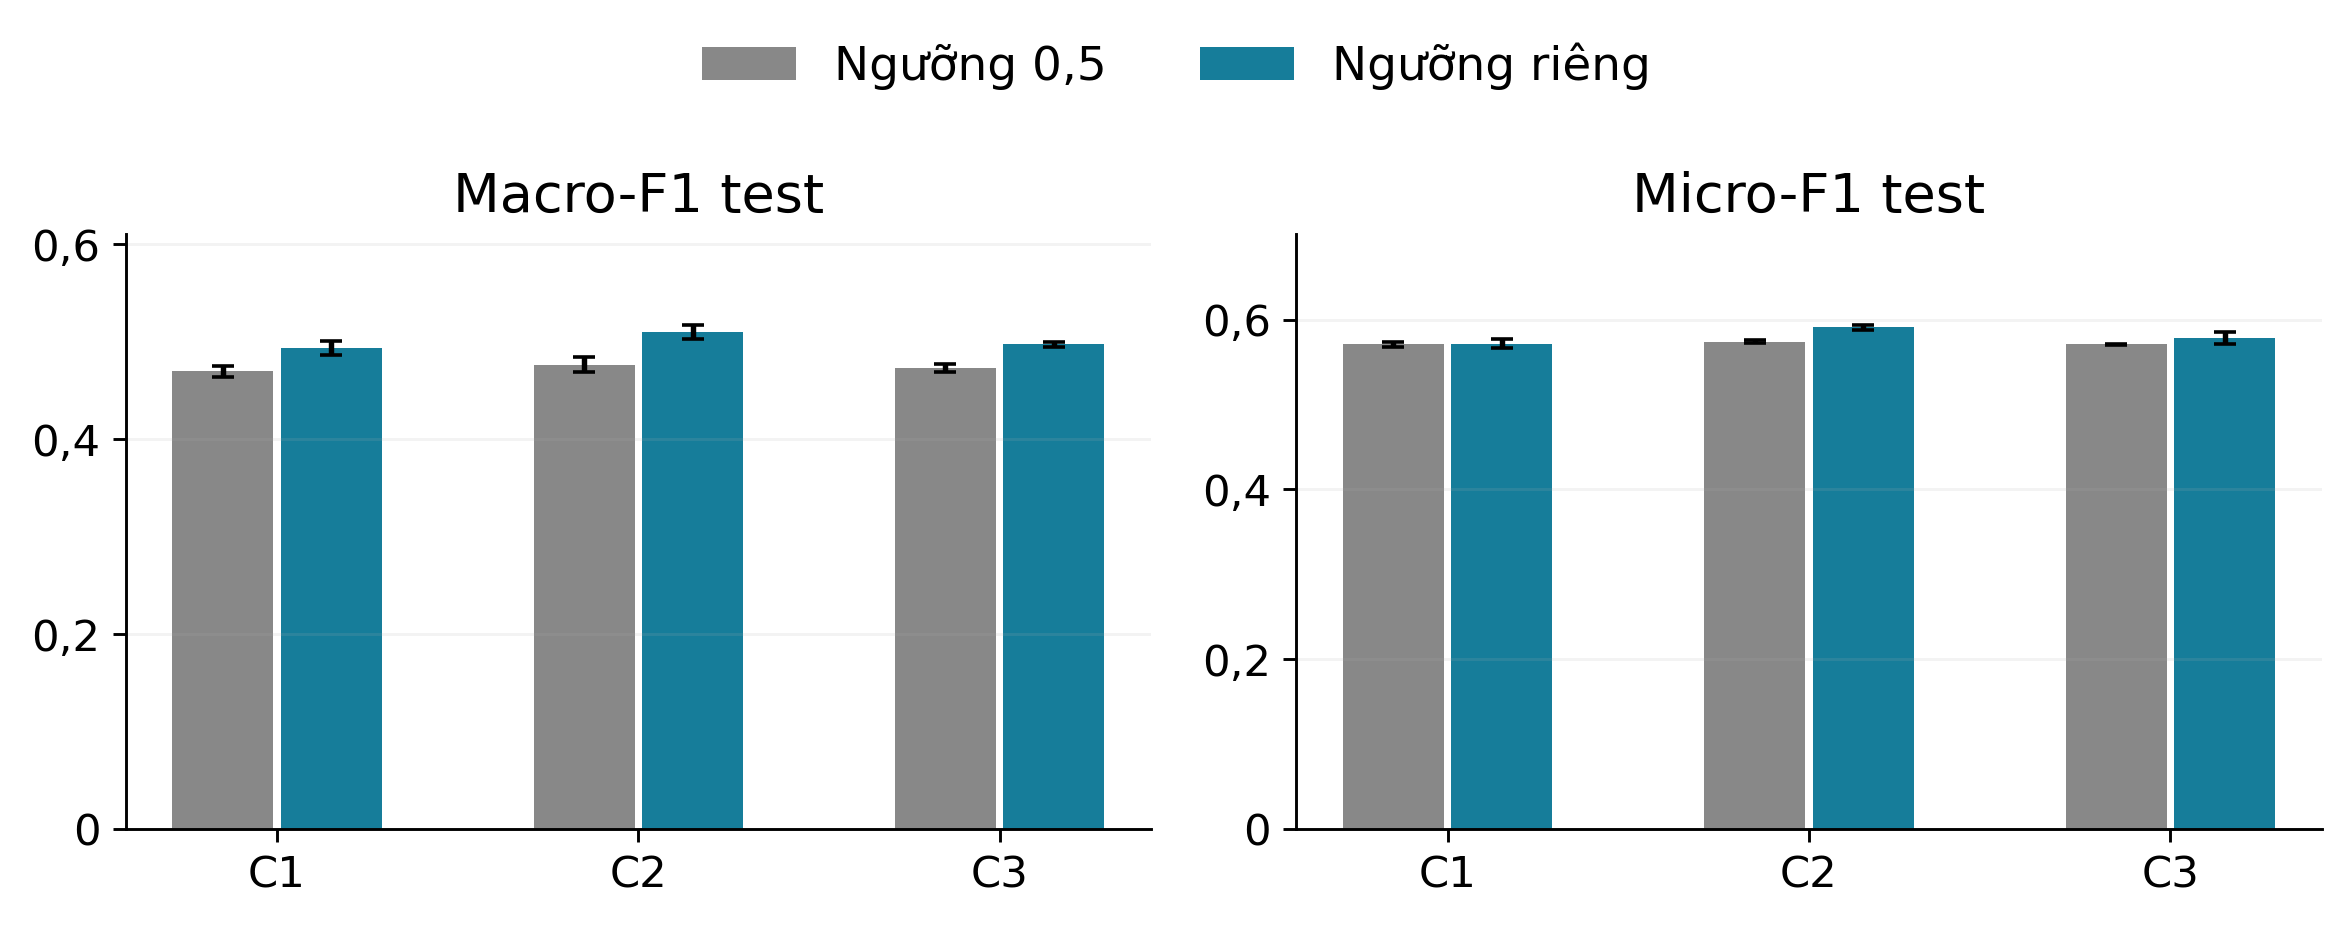

In [3]:
summary = actual.groupby(["model", "mode"])[["macro_f1", "micro_f1", "hamming_loss"]].agg(["mean", "std"])
display(summary.round(4))
display(Image(filename=str(MAIN / "charts/figures/test_f1_summary.png")))

## 3. Đường học và epoch chọn
Đường đứt đánh dấu checkpoint tốt nhất theo validation trong từng seed. Đường chấm là mốc validation của lượt chạy ban đầu; không phải kết quả test.

,model,seed,epoch,val_macro_f1,val_bce
6,BERT,42,7,0.455969,0.106145
13,BERT,123,6,0.461938,0.101499
22,BERT,2026,7,0.464495,0.105355
30,RoBERTa,42,7,0.484181,0.094248
39,RoBERTa,123,8,0.466438,0.097775
44,RoBERTa,2026,5,0.489797,0.088151
54,DistilBERT,42,7,0.468009,0.105085
63,DistilBERT,123,8,0.468118,0.106701
71,DistilBERT,2026,8,0.473971,0.105625


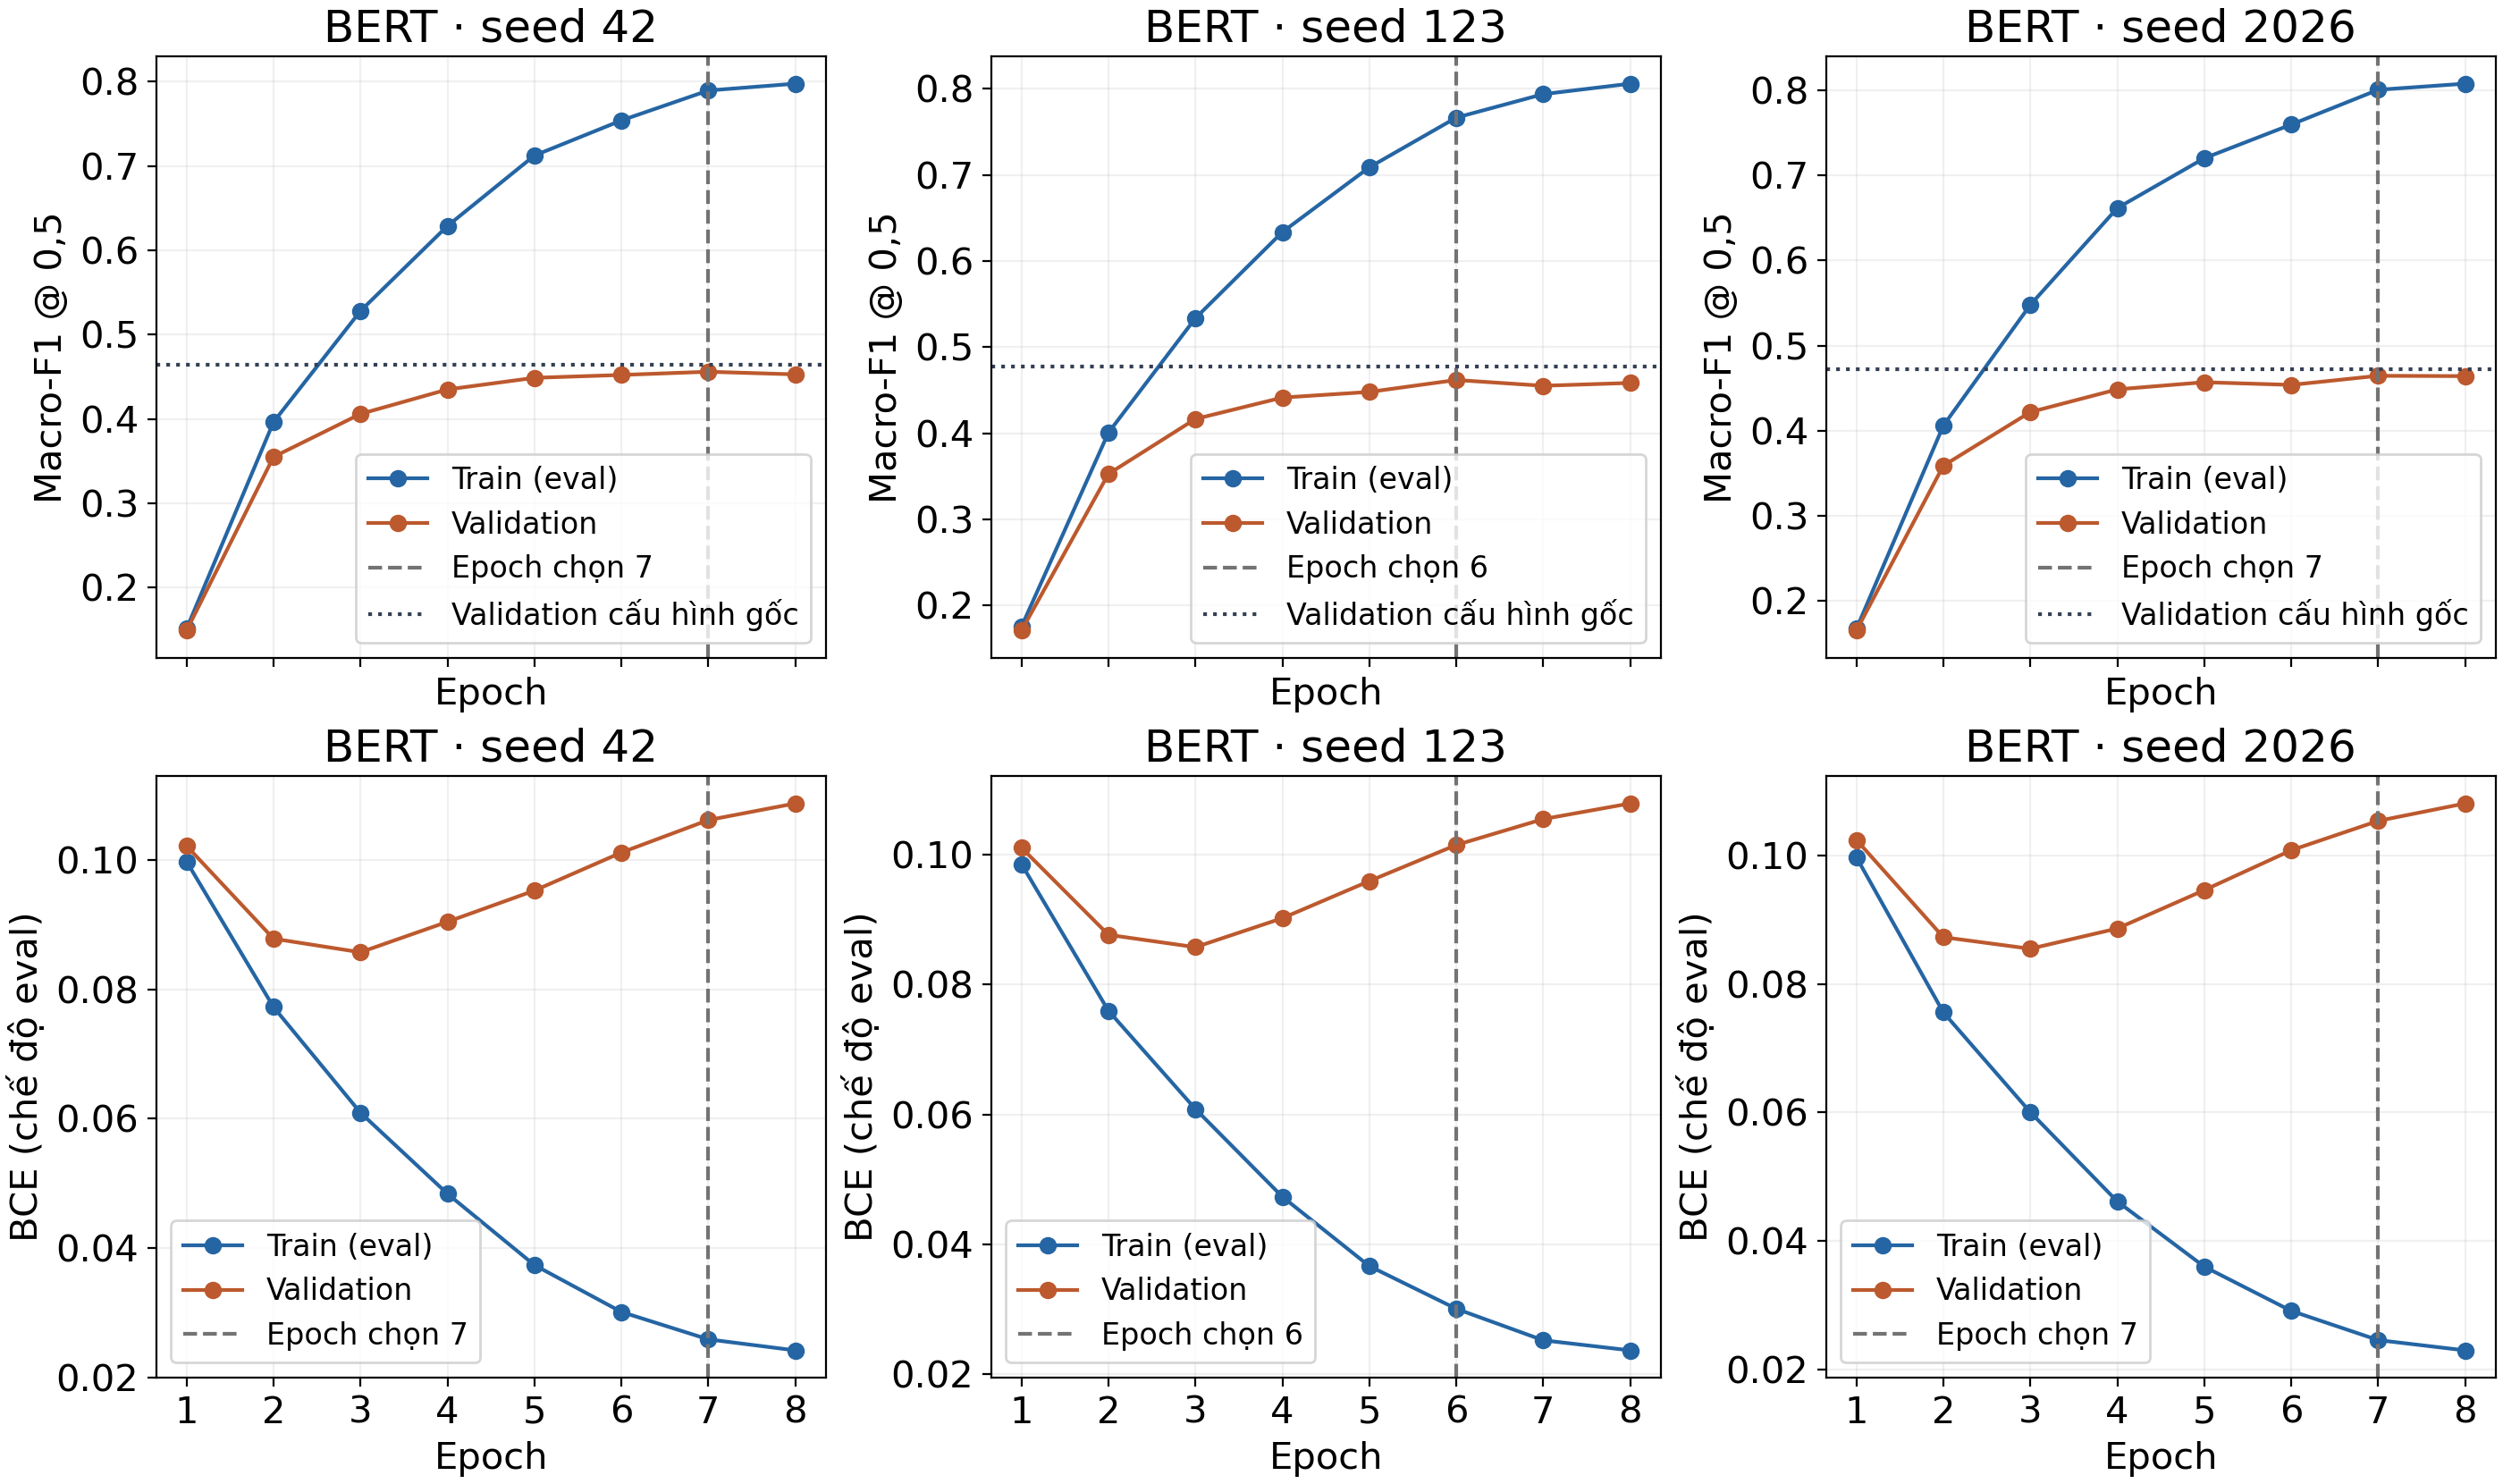

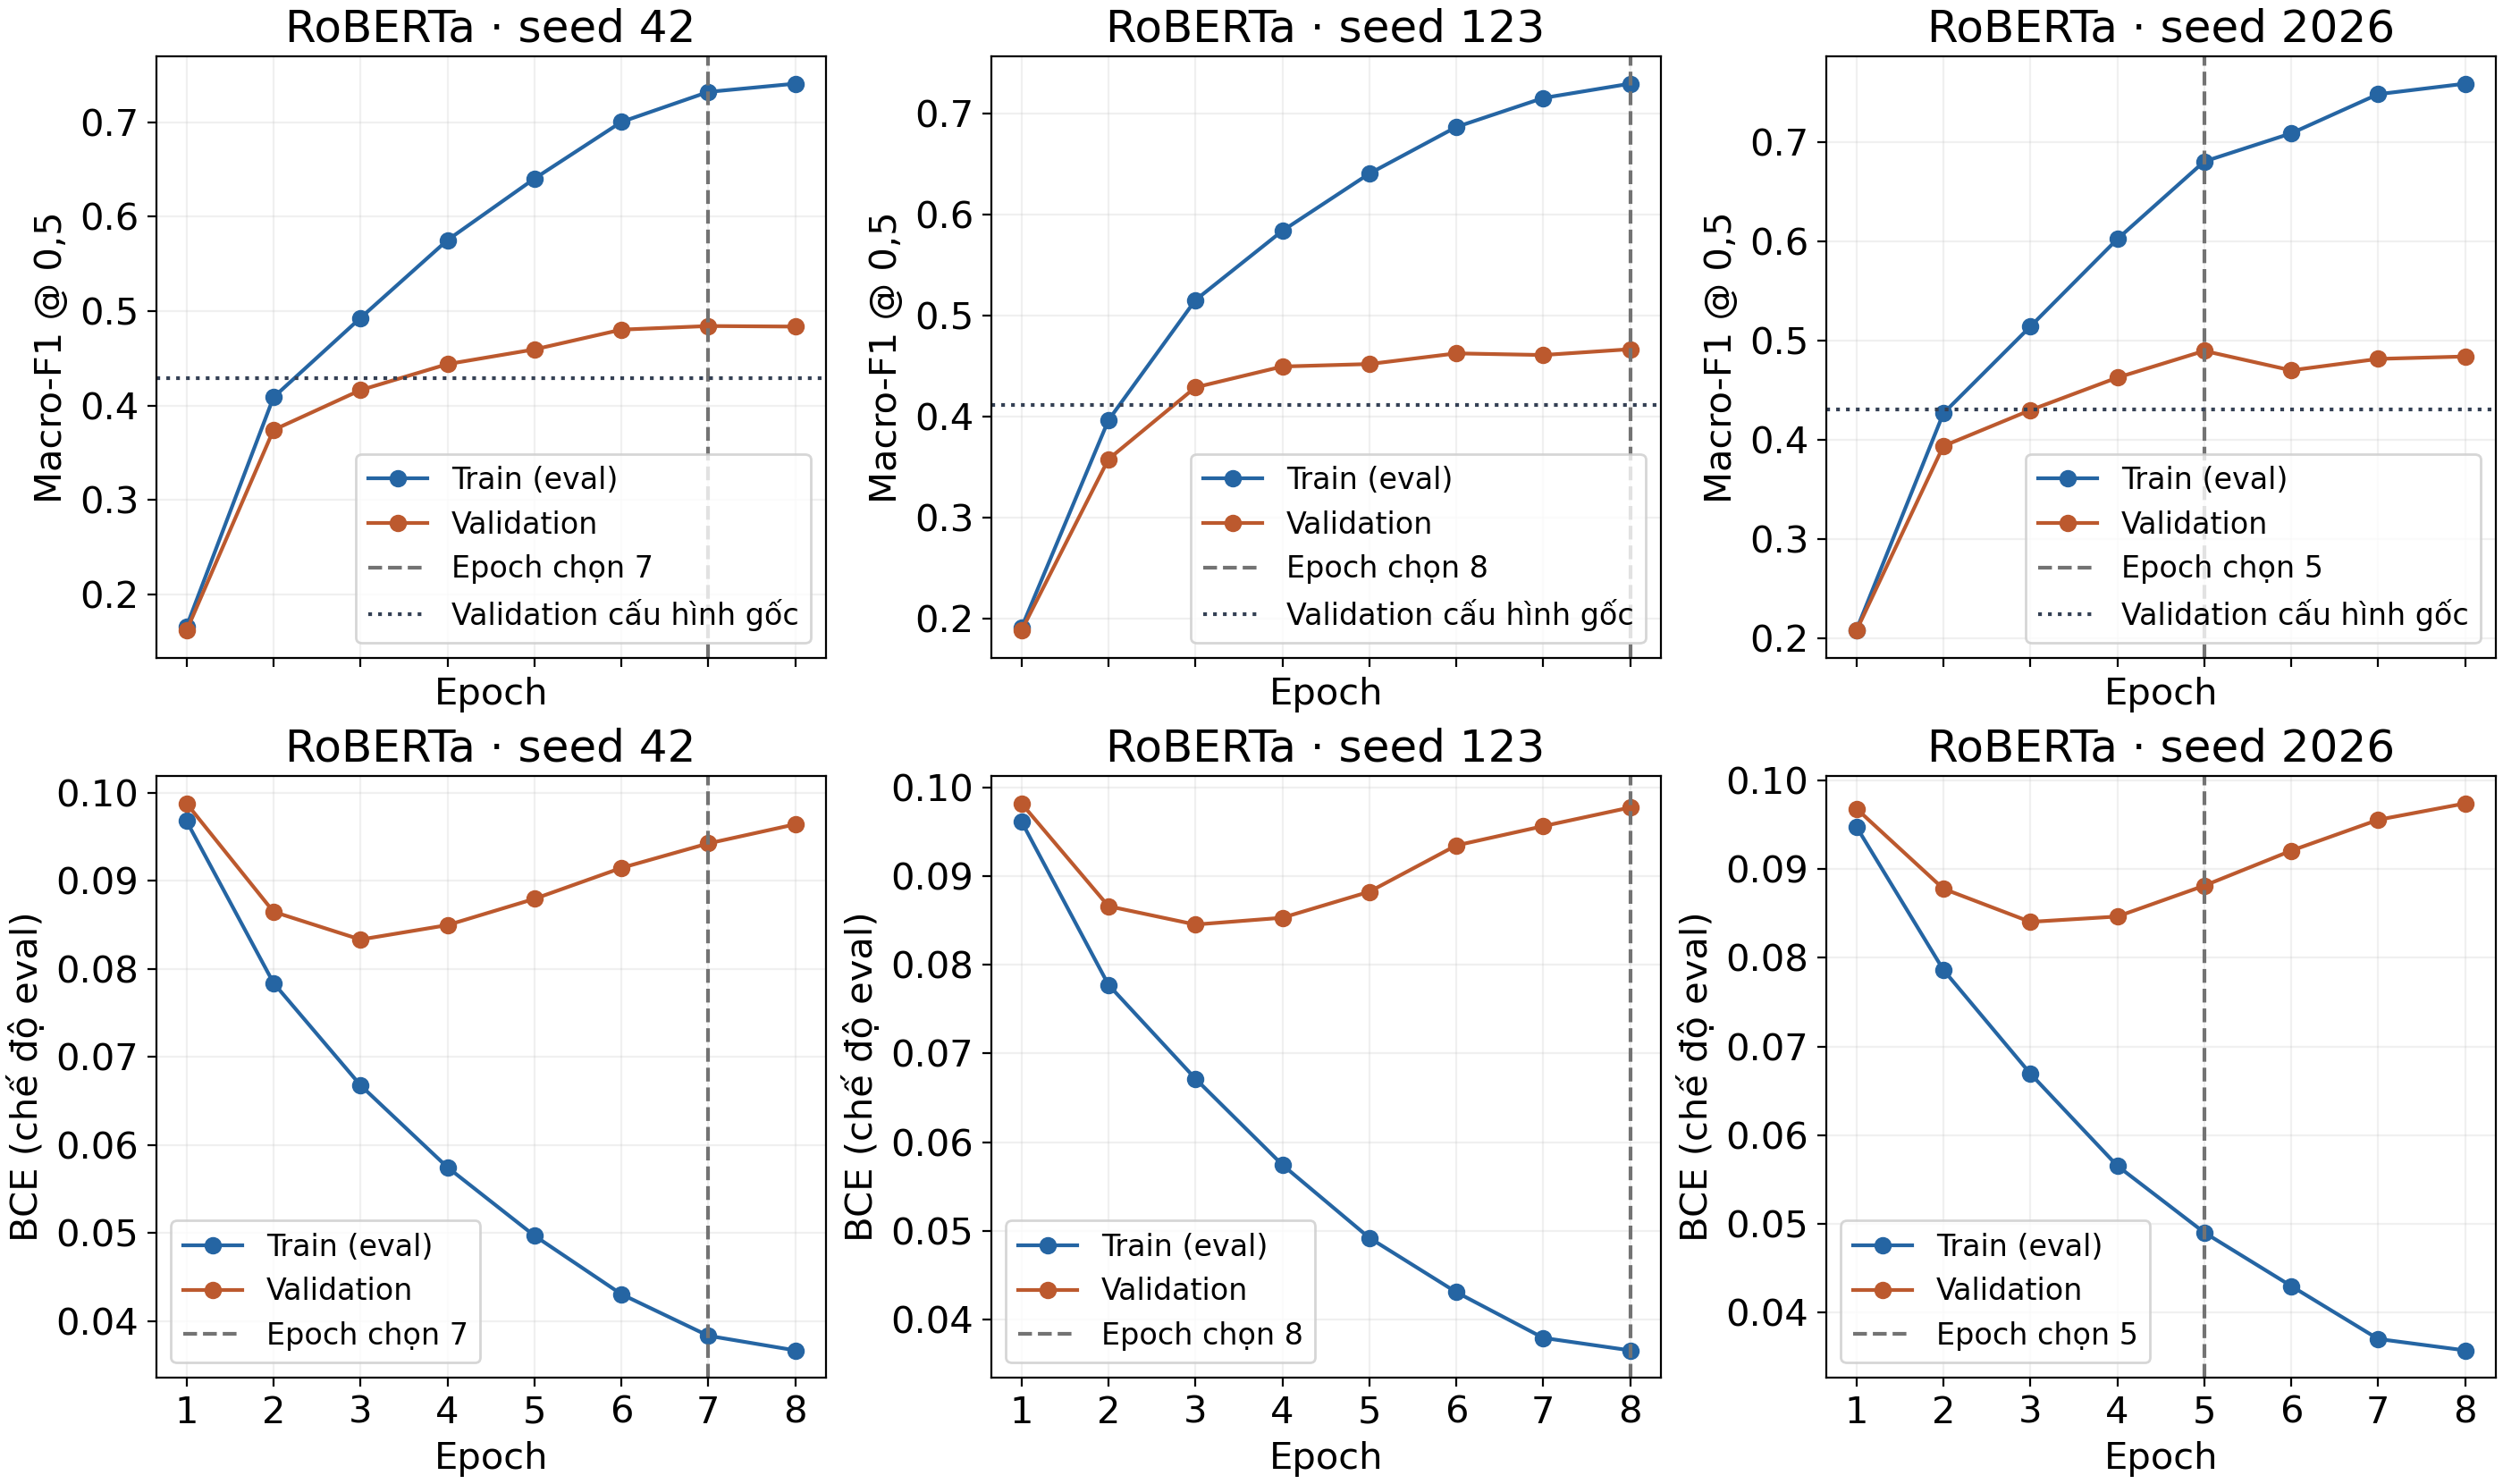

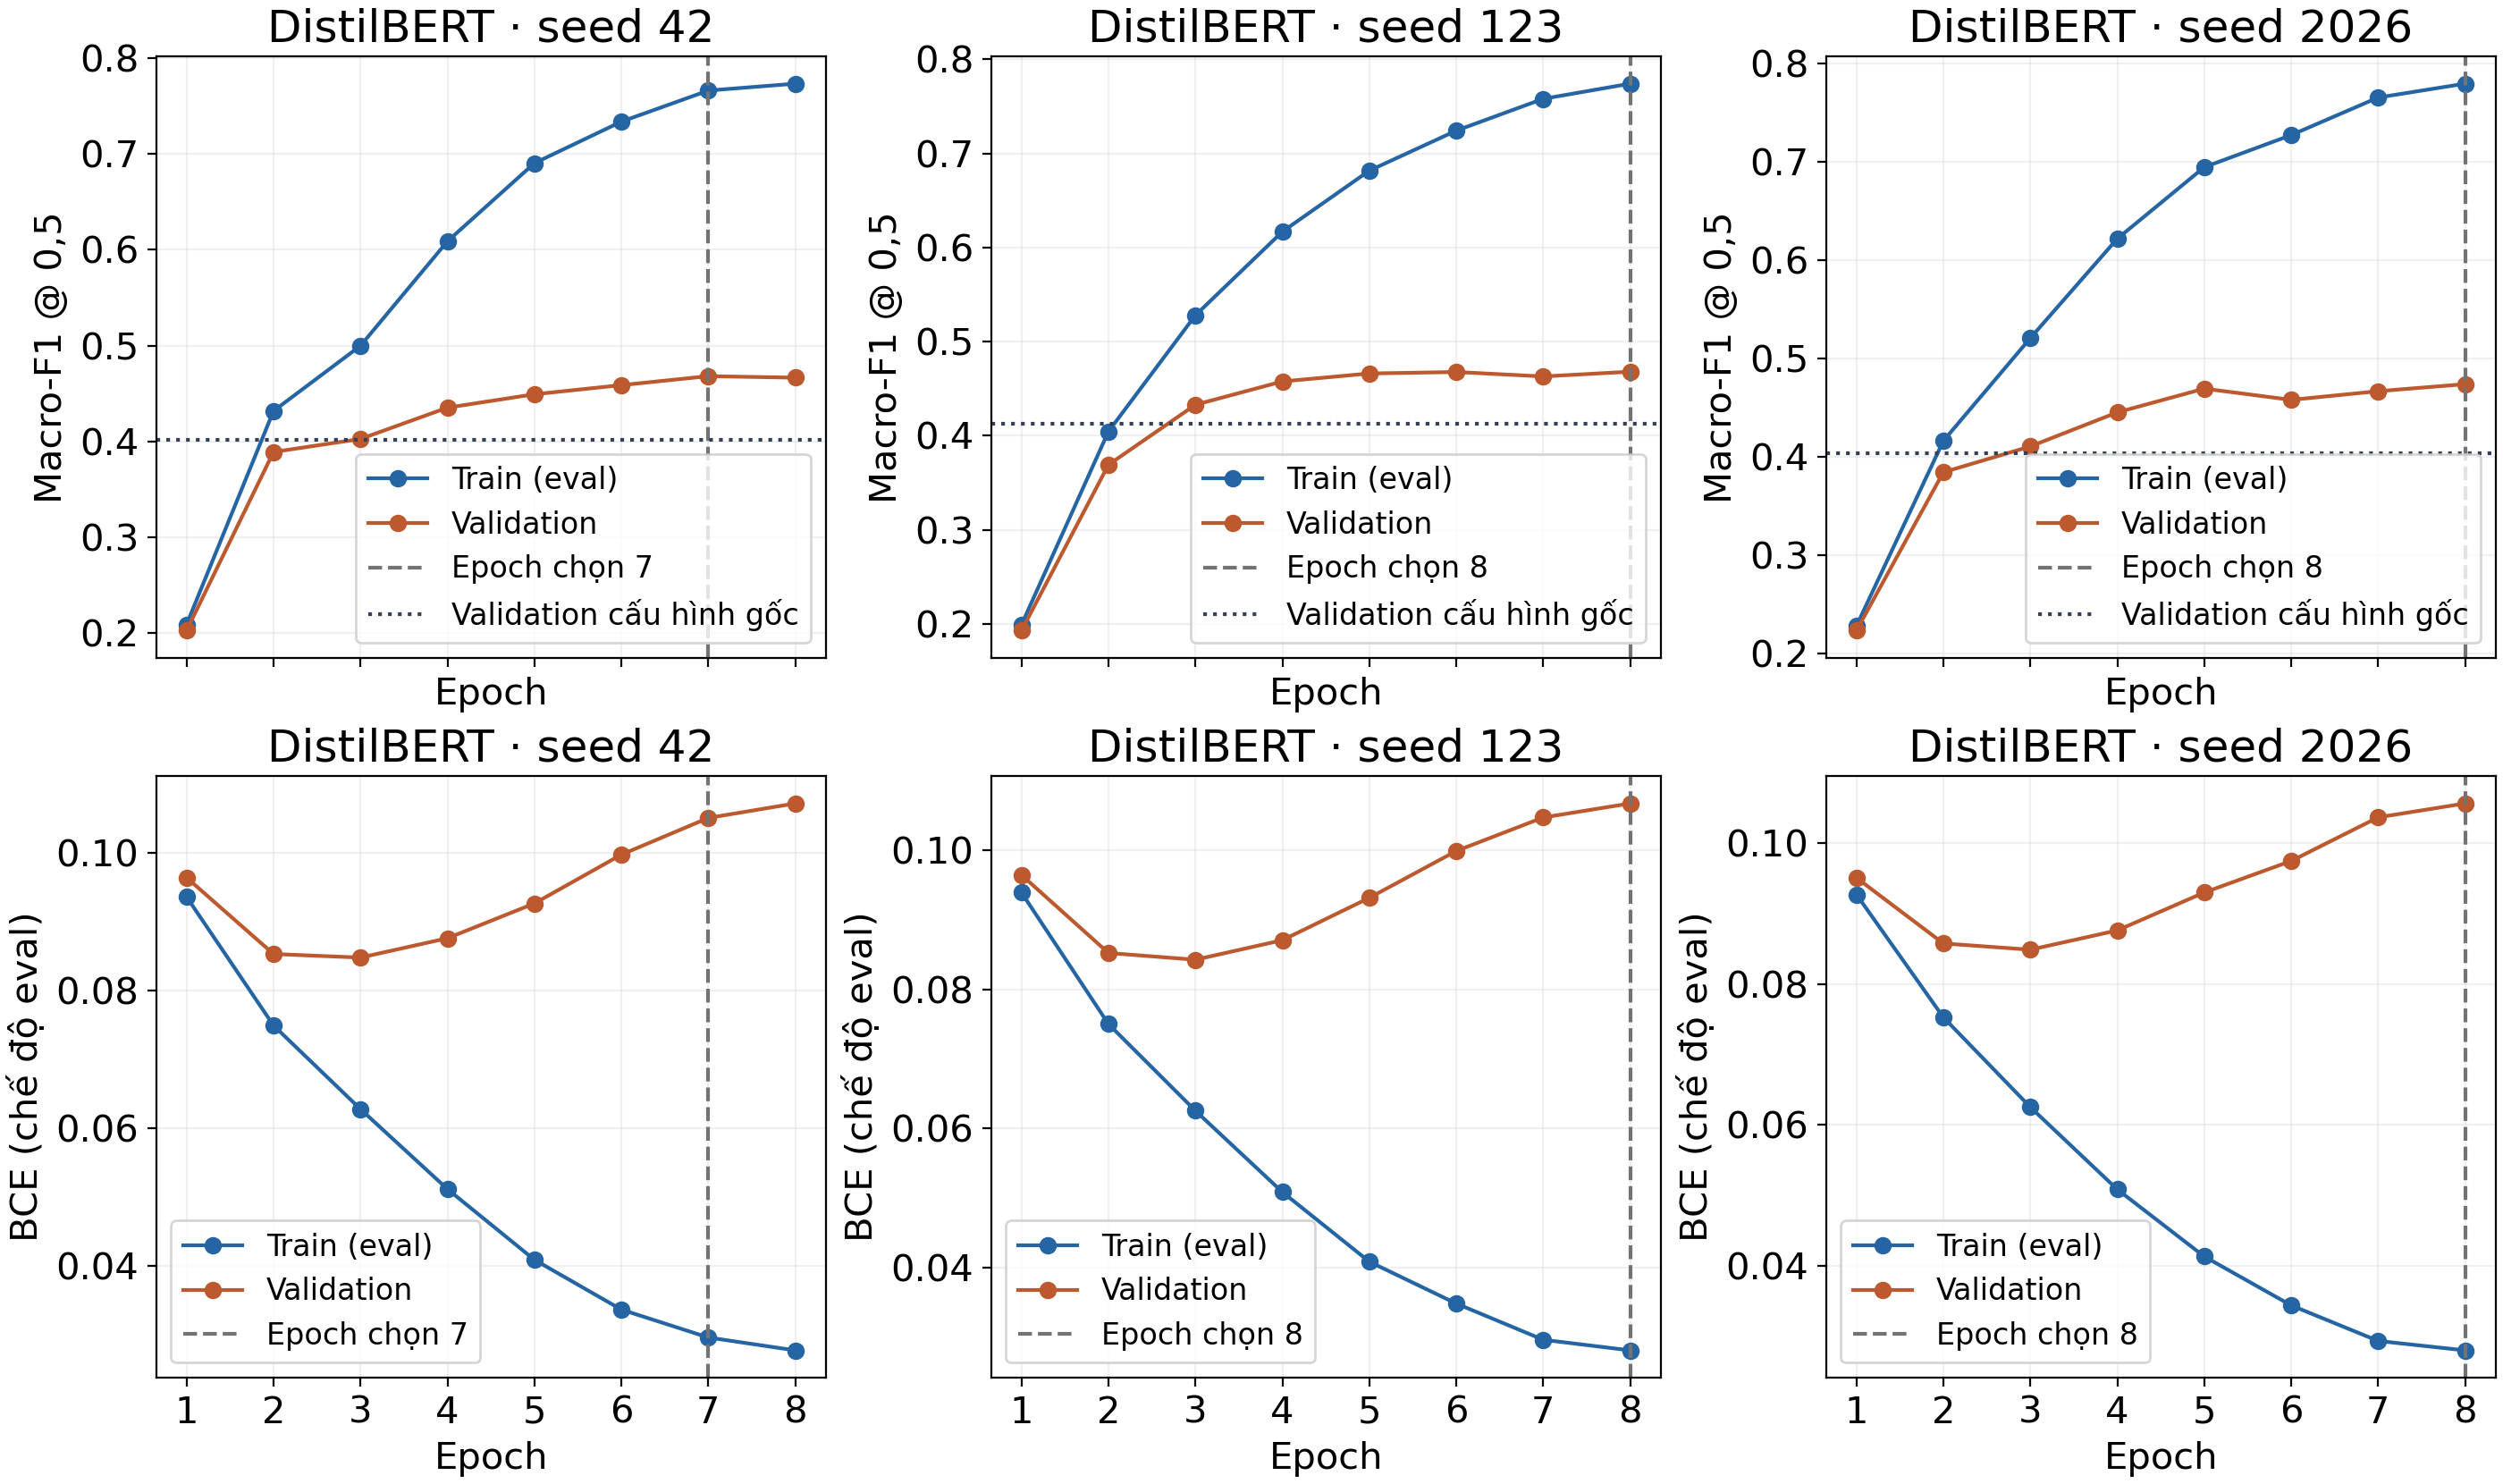

In [4]:
history = pd.read_csv(ROOT / "sweep_log.csv")
chosen = history[history.selected == 1][["model", "seed", "epoch", "val_macro_f1", "val_bce"]]
assert len(history) == 72 and len(chosen) == 9
display(chosen.round(6))
for name in ("BERT", "RoBERTa", "DistilBERT"):
    display(Image(filename=str(ROOT / "figures" / ("sweep_"+name+".png"))))

## 4. Kiểm tra overfit với checkpoint ban đầu
Đối chiếu trên toàn bộ train/validation, cùng eval mode, AMP fp16 và batch16. C2/C3 có mốc ba epoch thực tế; BERT cũ là bốn epoch và learning rate khác. Đây là chẩn đoán sau huấn luyện, không dùng test để chọn lại epoch.

,architecture,seed,original_epochs,selected_epoch,old_gap_macro_f1,selected_gap_macro_f1,old_val_bce,selected_val_bce,selected_minus_original_saved_val_f1
0,bert,42,4,7,0.264199,0.333544,0.094315,0.106145,-0.008179
1,bert,123,4,6,0.250426,0.304761,0.091837,0.101499,-0.015357
2,bert,2026,4,7,0.249484,0.336083,0.093245,0.105355,-0.007850
3,roberta,42,3,7,0.059863,0.247892,0.083892,0.094248,0.055536
4,roberta,123,3,8,0.063906,0.263011,0.083959,0.097775,0.055385
5,roberta,2026,3,5,0.067250,0.190798,0.083688,0.088151,0.059174
6,distilbert,42,3,7,0.069215,0.298411,0.084445,0.105085,0.066173
7,distilbert,123,3,8,0.065563,0.306095,0.084083,0.106701,0.054892
8,distilbert,2026,3,8,0.069229,0.305243,0.084298,0.105625,0.069806


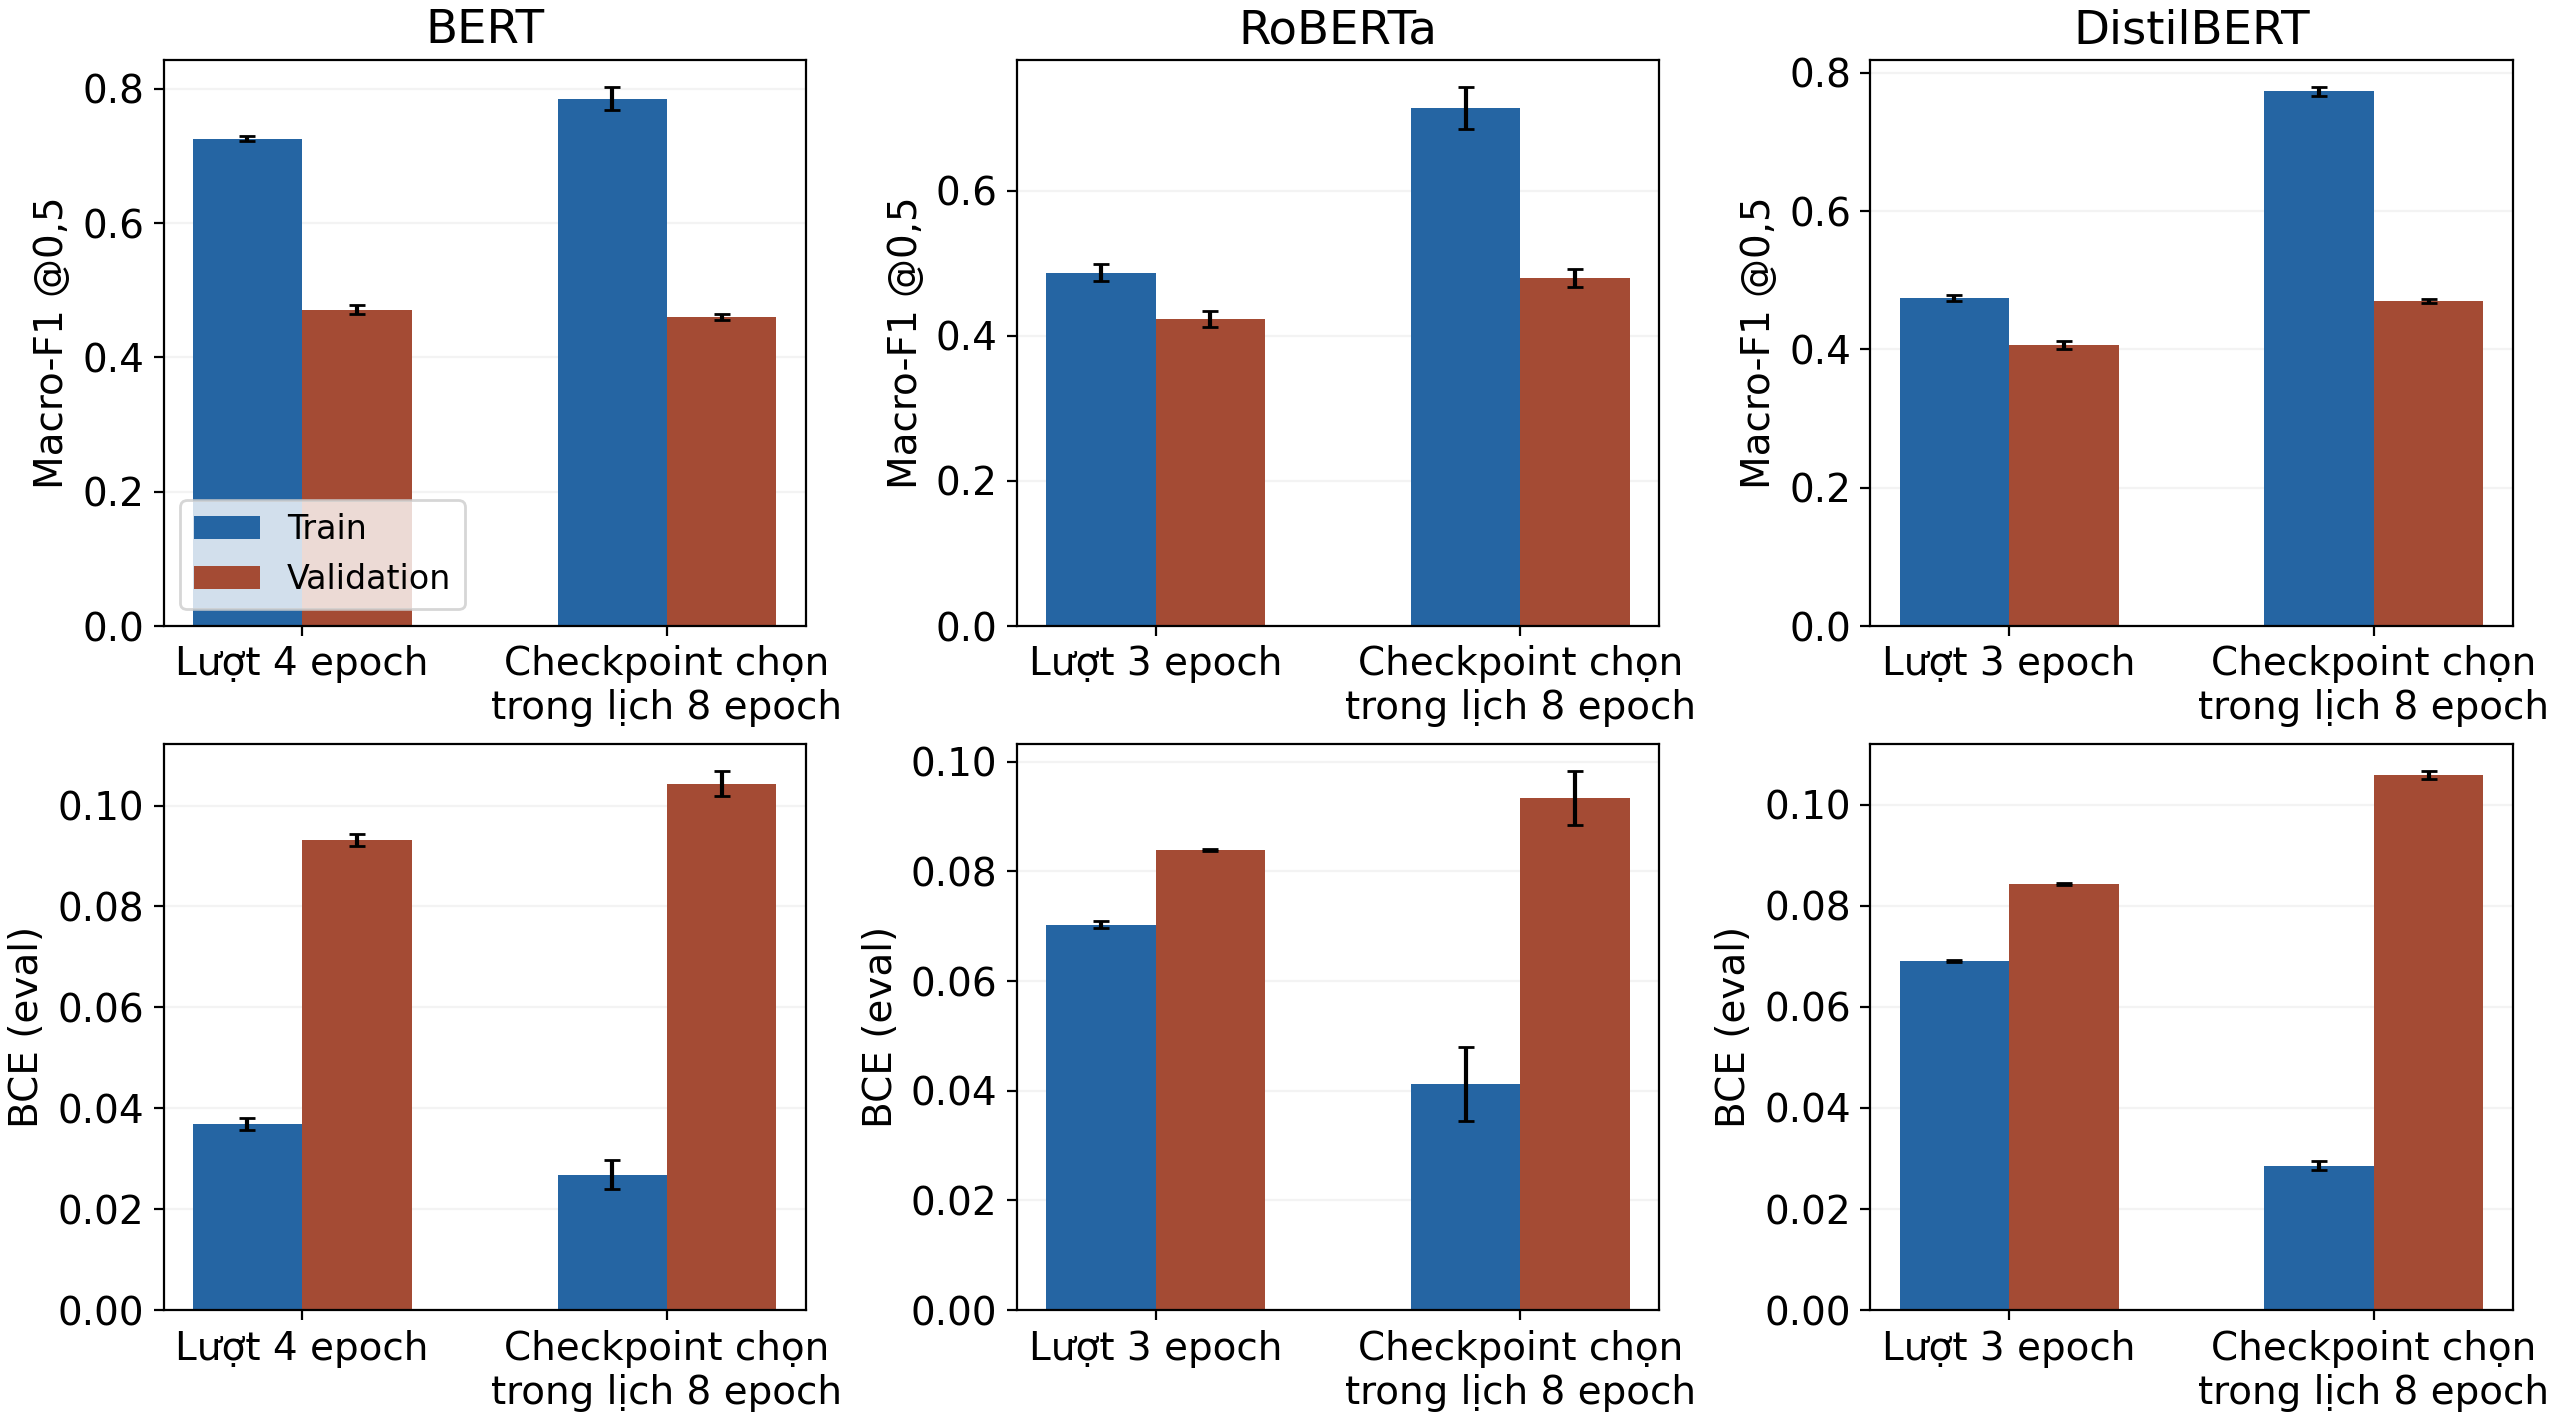

BERT: gap Macro-F1 train–validation tại checkpoint ban đầu là 0,2547 ± 0,0082, tại checkpoint được chọn trong ngân sách tám epoch là 0,3248 ± 0,0174. BCE validation đo cùng AMP thay đổi từ 0,0931 ± 0,0012 sang 0,1043 ± 0,0025. Trong lịch tám epoch, 3/3 seed có BCE train giảm nhưng BCE validation tăng từ epoch 3 đến epoch 8. Đây là dấu hiệu quá khớp theo loss cần đọc cùng F1, không phải bằng chứng rằng mọi tiêu chí đều kém đi. Macro-F1 validation tại checkpoint chọn chênh trung bình -0,0105 so với giá trị đã lưu của lượt ban đầu. Mốc BERT ban đầu là bốn epoch với learning rate khác, nên không gọi đây là so sánh chỉ thay từ ba lên tám epoch.
RoBERTa: gap Macro-F1 train–validation tại checkpoint ban đầu là 0,0637 ± 0,0037, tại checkpoint được chọn trong ngân sách tám epoch là 0,2339 ± 0,0381. BCE validation đo cùng AMP thay đổi từ 0,0838 ± 0,0001 sang 0,0934 ± 0,0049. Trong lịch tám epoch, 3/3 seed có BCE train giảm nhưng BCE validation tăng từ epoch 3 đến epoch 8. Đây là dấu hiệu quá khớ

In [5]:
audit = pd.read_csv(ROOT / "overfit_audit/overfit_comparison.csv")
display(audit[["architecture", "seed", "original_epochs", "selected_epoch", "old_gap_macro_f1", "selected_gap_macro_f1", "old_val_bce", "selected_val_bce", "selected_minus_original_saved_val_f1"]].round(6))
display(Image(filename=str(ROOT / "overfit_audit/overfit_comparison.png")))
for model in read(ROOT / "overfit_audit/summary.json")["models"]:
    print(model["interpretation"])

## So sánh test trước và sau
Bảng này mô tả kết quả sau khóa. Không dùng nó để chọn lại checkpoint. Cần đọc đồng thời Macro-F1, Micro-F1 và Hamming Loss.

In [6]:
before_after = pd.read_csv(MAIN / "report_data/test_before_after.csv")
display(before_after[before_after["mode"] == "tuned"].round(6))
print("Macro-F1 C2/C3 tăng, nhưng Micro-F1 cả ba giảm và Hamming Loss tăng; BERT còn thay learning rate so với lượt cũ.")

,architecture,mode,old_epoch_budget,old_learning_rate,new_epoch_budget,new_learning_rate,selected_epochs_42_123_2026,old_macro_f1_mean,old_macro_f1_std,new_macro_f1_mean,...,old_micro_f1_mean,old_micro_f1_std,new_micro_f1_mean,new_micro_f1_std,delta_micro_f1,old_hamming_loss_mean,old_hamming_loss_std,new_hamming_loss_mean,new_hamming_loss_std,delta_hamming_loss
1,bert,tuned,4,0.00005,8,0.00002,7/6/7,0.503752,0.009682,0.493794,...,0.590001,0.002851,0.571725,0.005126,-0.018275,0.037259,0.000338,0.040450,0.001581,0.003192
3,roberta,tuned,3,0.00002,8,0.00002,7/8/5,0.487201,0.015562,0.510117,...,0.604847,0.005666,0.590873,0.003315,-0.013975,0.036460,0.001366,0.037713,0.000226,0.001253
5,distilbert,tuned,3,0.00002,8,0.00002,7/8/8,0.486632,0.009338,0.497209,...,0.593544,0.004748,0.577897,0.006898,-0.015647,0.037732,0.000958,0.038919,0.001188,0.001187


Macro-F1 C2/C3 tăng, nhưng Micro-F1 cả ba giảm và Hamming Loss tăng; BERT còn thay learning rate so với lượt cũ.


## 5. Giới hạn diễn giải
Cả ba C trong bảng chính dùng LR 2×10⁻⁵, ngân sách tám epoch và checkpoint chọn riêng từng seed. Phép đối chiếu BERT với lượt cũ đồng thời thay LR và số epoch. Test đã từng được xem ở phiên bản báo cáo trước; đây không phải holdout mới. Không dùng số test để tinh chỉnh tiếp.

## Bảng B.3 — test của các lượt chạy ban đầu
Bảng giữ số cũ với cấu hình khác để đối chiếu, không thay bảng kết quả chính. BERT cũ có LR5e-5/bốn epoch; C2/C3 có LR2e-5/ba epoch. Không dùng cấu hình khác nhau để kết luận riêng về kiến trúc.

In [7]:
historical = pd.read_csv(MAIN / "report_data/original_test_summary.csv")
assert len(historical) == 6
columns = ["system", "threshold_mode", "macro_f1_mean", "macro_f1_std", "micro_f1_mean", "micro_f1_std", "hamming_loss_mean", "hamming_loss_std"]
display(historical[columns].round(4))
context = read(ROOT / "report_context.json")
print(context["reason"])
print(context["test_history"])
print(context["demo_limitation"])

,system,threshold_mode,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,hamming_loss_mean,hamming_loss_std
0,C_bert,fixed,0.4720,0.0045,0.5820,0.0040,0.0318,0.0003
1,C_bert,tuned,0.5038,0.0097,0.5900,0.0029,0.0373,0.0003
2,C_roberta,fixed,0.4219,0.0088,0.5803,0.0009,0.0295,0.0001
3,C_roberta,tuned,0.4872,0.0156,0.6048,0.0057,0.0365,0.0014
4,C_distilbert,fixed,0.4116,0.0035,0.5731,0.0017,0.0297,0.0001
5,C_distilbert,tuned,0.4866,0.0093,0.5935,0.0047,0.0377,0.0010


Bảng kết quả chính giữ cùng learning rate 2×10⁻⁵ và ngân sách tám epoch cho ba kiến trúc để hạn chế khác biệt về hai cài đặt này, không chọn cấu hình tốt nhất riêng cho từng mô hình. Vì vậy BERT trong bảng chính có Macro-F1 ngưỡng riêng 0,4938, thấp hơn 0,5038 ở lượt chạy ban đầu (Bảng B.3). Ngân sách tám epoch nằm trong kế hoạch kiểm tra giả thuyết C2/C3 học chưa đủ ở cấu hình ba epoch, đồng thời theo dõi F1 và BCE. Tám epoch là phạm vi khảo sát, chưa được chứng minh tối ưu chung.
Lịch tám epoch được quyết định sau khi nhóm đã xem kết quả test của các lượt chạy ban đầu (xem mục 6.2); các lựa chọn của bộ hiện tại (checkpoint, đại diện, ngưỡng) được khóa bằng validation trước đánh giá test.
Demo hiện chạy cục bộ; chưa có đường dẫn demo công khai để truy cập từ máy khác. Mã nguồn và gói checkpoint đã được công bố để tải và chạy lại ứng dụng.


## Kiểm độc lập các bảng báo cáo
Chạy `python experiments/best_epochs_20261103/verify_report_tables.py` từ gốc repository. Lệnh tính lại từ điểm dự đoán và đối chiếu cả bảng lịch sử; không huấn luyện lại.